# Example: Compute the Probability of Profit and Exercise for a Call Contract
In this example, we'll compute the Probability of Profit (POP) for a __short__ call option contract. If we sell a call, how likely are we to profit, and does Delta estimate the probability that the call is exercised?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Calculate breakeven points for call option contracts:__ Compute the share price at expiration where the option position transitions from profit to loss for both buyers and sellers.
> * __Project future share price distributions using two methods:__ Use the GBM model with risk-neutral drift and implied volatility to generate log-normal distributions, and construct a Normal distribution using implied volatility for quick estimates.
> * __Estimate probability of profit and probability of exercise:__ Apply the CDF of the projected share price distribution at the breakeven point to calculate the probability of profit, and at the strike price to calculate the probability of exercise, then compare the probability of exercise with Delta.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load an end-of-day options chain from the course's options archive, which holds the chains of 31 tickers captured after each close from April 13 to October 16, 2026. [The `MyOptionsEODChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsEODChainDataSet) returns the chain for one ticker, trading session, and expiration, with the share price on that session. Store the data in the `metadata::Dict{String,Any}` and `optionschain::DataFrame` variables.

In [2]:
ticker = "NVDA"; # underlying ticker: any of the 31 tickers in the archive
quote_date = Date(2026, 10, 8); # trading session of the quotes
target_dte = 45; # days to expiration target, one of the archive's ladder values (2, 7, 14, 30, 45)

metadata, optionschain = let

    # initialize: the first call downloads the archive (about 112 MB) -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date); # every expiration that session

    # keep the expiration matched to the target -
    expiration = filter(:target_dte => ==(target_dte), session.data).expiration |> first;
    options_dataset = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date, expiration = expiration);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

__Scenario:__ Suppose we sold the call whose strike price is closest to 3% above the share price, among the calls with an implied volatility in the archive. We'll use the mid quote, halfway between the bid and the ask, as the premium. Let's select that contract and store it in the `contract::DataFrameRow` variable:

In [3]:
contract = let

    # initialize -
    Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
    calls = filter(row -> row.type == "call" && !ismissing(row.implied_vol), optionschain);

    # the strike closest to 3% above the share price -
    i = argmin(abs.(calls.strike .- 1.03*Sₒ));
    calls[i, :] # return
end;

Which contract did we sell?

In [4]:
select(DataFrame(contract), :type, :strike, :bid, :ask, :mid, :implied_vol, :delta) # the columns we use; the chain has 19

Row,type,strike,bid,ask,mid,implied_vol,delta
,String,Float64,Float64,Float64,Float64,Float64?,Float64?
1,call,235.0,9.79,9.97,9.88,0.3543,0.4833


### Constants
Finally, let's set some constants we'll use later in this notebook. The risk-free rate is the yield of the 13-week Treasury bill on the quote date, converted to continuous compounding. The comments describe the constants, their units, and permissible values:

In [5]:
Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
DTE = metadata["DTE"]; # days to expiration (days)
Δt = (1/365); # one calendar day, expressed in years
T = DTE*Δt; # time to expiration (years)
K = contract.strike; # strike price of the call (USD/share)
P = contract.mid; # premium: the mid quote (USD/share)
IV = contract.implied_vol; # implied volatility (decimal, 1/sqrt(year))
Δ_quote = contract.delta; # the archive's Delta for this call (USD/share per USD/share)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-08 (0.0418 on 2026-10-16), U.S. Treasury Daily Treasury Bill Rates (accessed 2026-10-19); update it if you change quote_date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)

Let's collect these inputs in one table:

In [6]:
let
    # the inputs every calculation in this notebook shares -
    df = DataFrame(
        quantity = ["ticker", "quote date", "expiration", "days to expiration", "share price Sₒ", "strike price K",
            "premium P (mid quote)", "implied volatility", "Delta (archive quote)", "time to expiration T", "risk-free rate gᵧ"],
        value    = Any[ticker, metadata["quote_date"], metadata["expiration_date"], DTE, Sₒ, K,
            P, IV, Δ_quote, round(T, digits = 4), round(gᵧ, digits = 4)],
        units    = ["", "", "", "days", "USD/share", "USD/share", "USD/share", "1/sqrt(year)", "", "years", "1/year"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ----------------------- ------------ --------------
  quantity                     value   units        
 ----------------------- ------------ --------------
  ticker                        NVDA
  quote date              2026-10-08
  expiration              2026-11-20
  days to expiration              43   days
  share price Sₒ              230.57   USD/share
  strike price K               235.0   USD/share
  premium P (mid quote)         9.88   USD/share
  implied volatility          0.3543   1/sqrt(year)
  Delta (archive quote)       0.4833
  time to expiration T        0.1178   years
  risk-free rate gᵧ           0.0413   1/year
 ----------------------- ------------ --------------


Next, we construct a contract model for the call. We begin by building an instance of the [MyAmericanCallContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel) using the [custom build(...) method for this type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). 

The [build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}) takes two arguments: the type of thing we want to build, and a [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) containing the strike price $K$, the premium paid for the option, the time to expiration in the `DTE` field (units: years), the `sense` = 1 (long), the number of contracts in the `copy` field and the (decimal) implied volatility (IV) in the `IV` field.

We save the call option contract model in the `call_option_model::MyAmericanCallContractModel` variable:

In [7]:
call_option_model = build(MyAmericanCallContractModel, (
    K = K, 
    premium = P, # mid quote
    DTE = T, # time to expiration (years)
    sense = 1, # long contract
    copy = 1,
    IV = IV # must be a decimal
));

___

## Task 1: Compute the break-even points for long and short calls
In this task, we'll compute the breakeven price of our short call contract. The breakeven at expiration for both a long or short call contract is the share price $B_{c}$ at expiration such that the profit $P_{c}(K, B_{c}) = 0$. Thus, for our call, the breakeven share price $B_{c}$ USD/share would be:
$$
\begin{align*}
B_{c} &= K + \mathcal{P}_{c}(K,S(0))
\end{align*}
$$
For the buyer to make money, the share price must be above the breakeven price $B_{c}$. For the seller to make money, the share price must remain below the breakeven price.

`Unhide` the code block below to see how we plotted the profit diagram at expiration for long and short call positions on our contract:

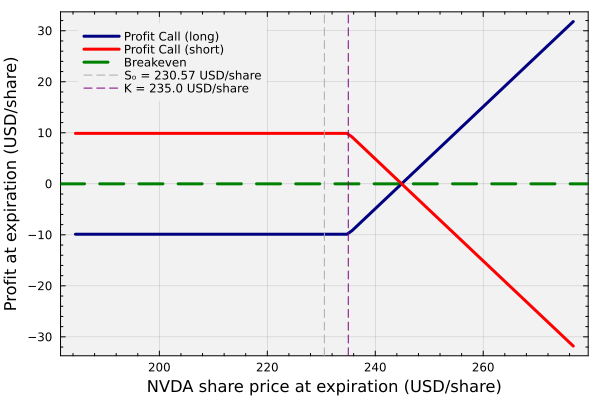

In [8]:
let
    N = 100; # how many points do we want?
    β = range(0.8,stop=1.2, length=N) |> collect;
    ST = Sₒ.*β; # future share price at expiration
    θ = -1; # we are in the short position

    # compute the payoff of the contract -
    payoff_array_long = payoff([call_option_model], ST); # this is always computed for a LONG contract
    profit_array_long = payoff_array_long[:,3] .- P;
    profit_array_short = θ*(payoff_array_long[:,3] .-P);

    # let's visualize
    plot(payoff_array_long[:,1], profit_array_long, c=:navy, lw=3, label="Profit Call (long)", legend=:topleft)
    plot!(payoff_array_long[:,1], profit_array_short, c=:red, lw=3, label="Profit Call (short)")
    hline!([0.0], c=:green, lw=3, ls=:dash, label="Breakeven")
    vline!([Sₒ], lw=1, c=:gray67, ls=:dash, label="Sₒ = $(Sₒ) USD/share")
    vline!([K], lw=1, c=:purple, ls=:dash, label="K = $(K) USD/share")
    xlabel!("$(ticker) share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit at expiration (USD/share)", fontsize=18)
    plot!(bg="gray95", background_color_outside="white", framestyle = :box, 
        fg_legend = :transparent, xminorticks = true, yminorticks = true);
end

Compute the break-even price for the call contract and store this in the `computed_breakeven_price::Float64` variable:

In [9]:
computed_breakeven_price = K + P

244.88

### Check: Is the profit zero at the computed breakeven?
At $S(T) = B_{c}$, the buyer's and the seller's profit should both be zero. Let's compute both with the [profit(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.profit), using a second contract model with `sense = -1` for the seller, and confirm the result using the [Julia @assert macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert) in combination with the [Julia isapprox(...) function](https://docs.julialang.org/en/v1/base/math/#Base.isapprox).

> __Test:__ If the profit at the `computed_breakeven_price` is _not_ approximately zero for either position, then an [AssertionError](https://docs.julialang.org/en/v1/base/base/#Core.AssertionError) is thrown.

So what do we get?

In [10]:
let
    # initialize: the seller's contract model -
    short_call_model = build(MyAmericanCallContractModel, (K = K, premium = P, DTE = T, sense = -1, copy = 1, IV = IV));

    # profit at the breakeven (USD/share): column 2 is the buyer, column 3 the seller -
    profit_array = profit([call_option_model, short_call_model], [computed_breakeven_price]);

    # one contract: 100 shares per contract -
    df = DataFrame(
        quantity = ["breakeven price B_c", "premium the seller receives for one contract",
            "buyer's profit at B_c", "seller's profit at B_c"],
        value    = [computed_breakeven_price, 100*P, round(profit_array[1,2], digits = 8) + 0.0, round(profit_array[1,3], digits = 8) + 0.0], # + 0.0 prints -0.0 as 0.0
        units    = ["USD/share", "USD", "USD/share", "USD/share"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.2f", [2])],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks -
    @assert isapprox(profit_array[1,2], 0.0; atol = 1e-10) "the buyer's profit is not zero at the breakeven"
    @assert isapprox(profit_array[1,3], 0.0; atol = 1e-10) "the seller's profit is not zero at the breakeven"
end

 ---------------------------------------------- -------- -----------
  quantity                                        value   units     
 ---------------------------------------------- -------- -----------
  breakeven price B_c                            244.88   USD/share
  premium the seller receives for one contract   988.00   USD
  buyer's profit at B_c                            0.00   USD/share
  seller's profit at B_c                           0.00   USD/share
 ---------------------------------------------- -------- -----------


___

## Task 2: Construct a single asset GBM model of the share price
In this task, we'll use geometric Brownian motion to compute the distribution of future share prices at expiration $S(T)$ of the call contract. Despite a few shortcomings, a nice feature of geometric Brownian motion is that it has a convenient analytical solution:
$$
\begin{equation*}
S_{t} = S_{0}\;\exp\Biggl[\left(\mu-\frac{\sigma^{2}}{2}\right)\left(t - t_{0}\right) + (\sigma\sqrt{t-t_{0}})\;{Z_{t}(0,1)}\Biggr]
\end{equation*}
$$
where $S_{0}$ is the initial share price at $t_{0}$, and $Z_{t}(0,1)$ is a standard normal random variable drawn at time $t$. Geometric Brownian motion will produce a future share price distribution that follows a log-normal distribution, with expectation and variance of the form:
$$
\begin{align*}
\mathbb{E}\left(S_{t}\right) &= S_{0}\;\exp\left(\mu(t-t_{0})\right)\\
\text{Var}\left(S_{t}\right) &= S_{0}^{2}e^{2\mu\cdot(t-t_{0})}\left[e^{\sigma^{2}(t-t_{0})} - 1\right]
\end{align*}
$$
where $(t-t_{0})$ is the time interval. We'll use the analytical solution to compute the distribution of share price values at $t = T$, i.e., at the contract's expiration.

Next, we'll build an instance of the [MyGeometricBrownianMotionEquityModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) which holds values for the drift `μ` and volatility `σ` parameters using a [custom build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.build-Tuple{Type{MyGeometricBrownianMotionEquityModel},%20NamedTuple}). We set the drift parameter to the risk-free rate $g_{y}$ (because options use a risk-neutral probability measure), and the volatility to the contract's implied volatility. With these two choices, the projected share price distribution is the one behind the L9a Black–Scholes–Merton formulas.

We save the GBM equity model in the `model::MyGeometricBrownianMotionEquityModel` variable:

In [11]:
model = build(MyGeometricBrownianMotionEquityModel, (
    μ = gᵧ, # risk-neutral drift: let's mess with this ...
    σ = IV  # implied volatility of the contract
));

Now that we have a populated [MyGeometricBrownianMotionEquityModel instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel), let's generate `number_of_samples` possible future share price values using the [sample(...) function exported by the VLQuantitativeFinancePackage.jl package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}).
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}) takes a `model::MyGeometricBrownianMotionEquityModel` instance as the first argument, along with the time values that we wish to sample: `T₁::Float64` is the start time, `T₂::Float64` is the stop-time (in units of `years`), `Δt::Float64` is the time step (in units of `years`), and `Sₒ::Float64` denotes the initial share price (in units of `USD/share`). Finally, we pass in the number of samples we want to generate in the `number_of_paths` argument.
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}) generates `number_of_paths` sample paths from $T_{1}\rightarrow{T}_{2}$ in steps of $\Delta{t}$. However, we only want the share prices at the contract's expiration, i.e., $T_{2} = T$. Thus, we pass the full `samples` array [using the Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) to a slicing operation where we select columns `2:end` of the last row (col 1 holds the time). We store the `number_of_paths` samples of the share price at $T_{2}$ in the `endpoint_samples::Array{Float64,1}` variable.

We fix the random seed, so we get the same samples every time we run the notebook. So what do we get?

In [12]:
endpoint_samples = let

    # initialize
    Random.seed!(5660); # reproducible samples
    number_of_samples = 50000; # how many samples do we want to generate?

    # compute the endpoint samples -
    endpoint = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0,
        T₂ = T,
        Δt = Δt,
        Sₒ = Sₒ
    ), number_of_paths = number_of_samples) |> samples -> samples[end,2:end]; # get last row from col 2 -> number_of_paths

    endpoint; # return
end

50000-element Vector{Float64}:
 239.26807323883853
 236.19503612782032
 211.20018198738762
 274.06079148499265
 211.9060559656463
 222.777114648386
 196.880961400135
 200.06413681750075
 278.46659227626185
 222.0817889385176
 214.76312951930373
 248.59318583625029
 267.77428825790355
   ⋮
 274.70450946368663
 221.2388564529165
 227.33503645731585
 172.57968702372193
 215.02460473584026
 201.95892607989677
 248.4917121955061
 242.61163799788608
 206.82248092490332
 160.29712707734933
 274.8196809001224
 197.7060250417657

### Check: Are future GBM share prices log-normally distributed?
We expect geometric Brownian motion to generate __log-normally distributed__ share prices. The analytical solution gives this distribution directly. The logarithm of the share price at expiration is normally distributed:
$$
\begin{equation*}
\ln S(T) \sim \mathcal{N}\left(\ln S_{0} + \left(\mu-\frac{\sigma^{2}}{2}\right)T,~\sigma^{2}T\right)
\end{equation*}
$$
Let's save this [LogNormal distribution exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) in the `d_gbm` variable. Its two arguments are the mean and the standard deviation of $\ln S(T)$:

In [13]:
d_gbm = LogNormal(log(Sₒ) + (model.μ - model.σ^2/2)*T, model.σ*sqrt(T));

Next, we check the samples against `d_gbm` with an [exact one-sample Kolmogorov-Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#HypothesisTests.ExactOneSampleKSTest).
> __Hypothesis:__ The `H0:null hypothesis` for the test is the data (endpoint samples generated using geometric Brownian motion) comes from the LogNormal distribution `d_gbm`. The alternative hypothesis `H1:alternative` is the samples are not drawn from `d_gbm`.

We reject the `H0:null hypothesis`, i.e., the `endpoint_samples` are not drawn from `d_gbm`, if the [pvalue](https://en.wikipedia.org/wiki/P-value) generated by the test is _less than_ some cutoff, e.g., `0.01`.

In [14]:
test_result = ExactOneSampleKSTest(endpoint_samples, d_gbm)

Exact one sample Kolmogorov-Smirnov test
----------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.00287703

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.8023

Details:
    number of observations:   50000


In [15]:
# checks -
@assert test_result |> pvalue > 0.01 # if this passes, then S(T) ~ d_gbm

`Unhide` the code block below to see how we plotted the future share price generated using a risk-neutral single asset geometric Brownian motion model parameterized using implied volatility.
> __What do we see?__ The simulated endpoint share prices (blue line) follow the analytic log-normal distribution `d_gbm` (red line), as the check above confirmed.

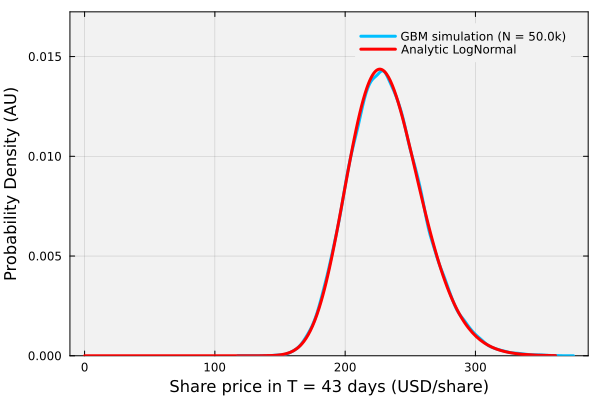

In [16]:
let
    density(endpoint_samples, lw=3, c=:deepskyblue1, label="GBM simulation (N = $(length(endpoint_samples)/1000)k)")
    plot!(d_gbm, lw=3, label="Analytic LogNormal", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent,
        ylims = (0, 1.2*pdf(d_gbm, mode(d_gbm)))) # keep the peak inside the frame
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Alternative: Future share price projection using implied volatility
Alternatively, we could use the __implied volatility__ to estimate the expected share price move over some time $0\rightarrow{T}$.
Suppose we construct a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal) $\mathcal{N}(\mu_{IV},\sigma_{IV})$ where the mean $\mu_{IV} = S_{0}\exp(g_{y}T)$, i.e., the risk-neutral future value of the current share price, or just $\mu_{IV}\approx{S}_{0}$ for short duration contracts, and the standard deviation $\sigma_{IV}$ is:
$$
\sigma_{IV} = S_{0}\cdot\text{IV}\cdot\sqrt{T}
$$
where the implied volatility IV is a decimal and $T$ is in years. This is only an approximate model of the future share price, and it has an issue:
> __Watch out!__ This model assumes a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal), which is problematic because it can emit negative share prices. One way to fix this issue is to use a [Truncated Normal distribution](https://juliastats.org/Distributions.jl/stable/truncate/#Truncated-Distributions) instead.

However, despite the potential issues, this model is __widely__ used to generate quick estimates of future share price ranges using the forward-looking implied volatility. Let's save the Normal IV distribution $\mathcal{N}(\mu_{IV},\sigma_{IV})$ in the `d_IV` variable:

In [17]:
d_IV = Normal(Sₒ*exp(gᵧ*T), Sₒ*IV*sqrt(T));

`Unhide` the code block below to see how we plotted the `d_gbm` and `d_IV` future share price densities at expiration.  

> __What do we see?__ The log-normal GBM share price distribution (blue line) is right-skewed and cannot admit negative share prices. However, the Normal IV distribution (red line) is symmetric around its mean $\mu_{IV}$ and can admit negative share prices, albeit with a small probability.

How do the two distributions compare?

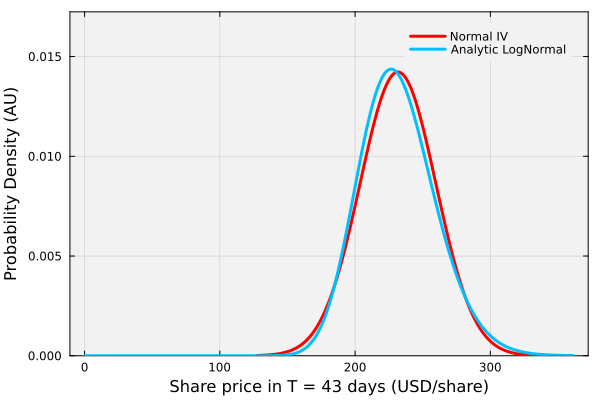

In [18]:
let
    plot(d_IV, lw=3, label="Normal IV", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(d_gbm, lw=3, label="Analytic LogNormal", c=:deepskyblue1,
        ylims = (0, 1.2*max(pdf(d_gbm, mode(d_gbm)), pdf(d_IV, mean(d_IV))))) # keep the peaks inside the frame
    
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

___

## Task 3: Estimate the probability of profit and exercise for our call contract
In this task, we estimate the probability of profit and the probability of exercise of our call contract, then compare the probability of exercise with Delta.

> __Probability of Profit (POP)__
>
> Given the ability to simulate future share price distributions, we can now compute the likelihood of seeing a particular range of values. Let's consider this contract from the buyer's and seller's perspectives:
> * __Buyer's perspective__: the share price at expiration $S(T)$ must be _greater than_ the breakeven price $B_{c}$ for the `call` contract to be profitable. The probability of profit can be calculated from the [cumulative distribution function of the share price](https://en.wikipedia.org/wiki/Cumulative_distribution_function), i.e., $P(S(T)>{B}_{c}) = 1 - F_{S}(B_{c})$ where $F_{S}(B_{c})$ is the cumulative distribution function evaluated at the breakeven price.
> * __Seller's perspective__: the share price at expiration $S(T)$ must be _less than_ the breakeven price $B_{c}$ for the `call` contract to be profitable. The probability of profit can be calculated from the same [cumulative distribution function](https://en.wikipedia.org/wiki/Cumulative_distribution_function), i.e., $P(S(T)\leq{B}_{c}) = F_{S}(B_{c})$.

We can query the [cumulative distribution function $F_{S}(B_{c})$](https://en.wikipedia.org/wiki/Cumulative_distribution_function) of the projected distributions `d_gbm` and `d_IV` using the [cdf(...) function exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.cdf-Tuple{UnivariateDistribution,%20Real}). For the simulated samples, the probability is the fraction of samples on the profitable side of $B_{c}$.

### Probability of profit (POP) table
`Unhide` the code block below to see how we developed a table displaying the probability of profit for our call from the buyer's and seller's perspectives.
> __Hypothesis:__ The simulated samples and `d_gbm` describe the same model, so their POP values should agree to within sampling error. Do they? How far is the Normal IV estimate from the other two?

So what are the results?

In [19]:
let 

    # initialize -
    B = computed_breakeven_price;
    number_of_samples = length(endpoint_samples);
    seller_POP_samples = count(endpoint_samples .≤ B)/number_of_samples; # fraction of samples at or below the breakeven

    # one row per perspective -
    table_df = DataFrame(
        perspective = ["buyer", "seller"],
        event = ["S(T) > B_c", "S(T) ≤ B_c"],
        GBM_samples = [1 - seller_POP_samples, seller_POP_samples],
        GBM_analytic = [1 - cdf(d_gbm, B), cdf(d_gbm, B)],
        normal_IV = [1 - cdf(d_IV, B), cdf(d_IV, B)]
    );
    pretty_table(table_df; column_labels = ["perspective", "profitable when", "GBM samples", "d_gbm", "d_IV"],
        formatters = [fmt__printf("%.4f", [3, 4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the samples agree with d_gbm to within five standard errors -
    standard_error = sqrt(cdf(d_gbm, B)*(1 - cdf(d_gbm, B))/number_of_samples);
    @assert abs(seller_POP_samples - cdf(d_gbm, B)) ≤ 5*standard_error "the simulated POP disagrees with d_gbm"
end

 ------------- ----------------- ------------- -------- --------
  perspective   profitable when   GBM samples    d_gbm     d_IV 
 ------------- ----------------- ------------- -------- --------
        buyer        S(T) > B_c        0.3042   0.3029   0.3191
       seller        S(T) ≤ B_c        0.6958   0.6971   0.6809
 ------------- ----------------- ------------- -------- --------


### Probability of exercise and Delta
We know that $\Delta$ measures the rate of change in the option's premium with respect to a `+1 USD/share` change in the underlying asset's price. However, one of the secret lives of $\Delta$ is its connection with the probability of exercise. Let's explore this connection.

> __Probability of Being In-the-Money (ITM)__: The absolute value of $\Delta$ is often used as an estimate of the probability that an option will expire ITM. For example, a delta of 0.40 suggests a 40% chance that the option will finish ITM at expiration. If an option finishes ITM, it has intrinsic value, meaning it can be exercised for a non-zero value. Conversely, if it finishes out-of-the-money (OTM), it expires worthless.

Let's explore this idea with our call contract. The archive quotes Delta for every contract, and we stored it in the `Δ_quote` variable.

__From the buyer's perspective:__ The buyer needs the share price to be $S(T) \geq K+\epsilon$ where $\epsilon > 0$ at expiration to have a __non-zero intrinsic (exercise) value__. Let's use $\epsilon=$ `0.01` USD/share. The probability of this case is the probability of exercise, $\text{POE} = P(S(T)>(K+\epsilon)) = 1 - F_{S}(K+\epsilon)$:

In [20]:
POE = 1 - cdf(d_gbm, K + (1/100)) # buyer's perspective

0.4294980151598192

__From the seller's perspective:__ The seller wants the option to expire out of the money (OTM), i.e., the seller gets to keep all the premium paid by the buyer. Thus, the seller wants $S(T) \leq K$. The probability of this case is given by $P(S(T) \leq K) = F_{S}(K)$:

In [21]:
P_OTM = cdf(d_gbm, K) # seller's perspective

0.5703645698019986

__The secret life of Delta:__ If $\Delta$ is the probability of being ITM, then $1-\Delta$ will be the probability of being OTM, which is the outcome the seller wants. In the L9a Black–Scholes–Merton model, a call's Delta is $N(d_{+})$, while the risk-neutral probability that it finishes ITM is $N(d_{-})$, where:
$$
\begin{align*}
d_{\pm} & = \frac{1}{\sigma\sqrt{T}}\left[\ln\left(\frac{S(0)}{K}\right) + \left(g_{y}\pm\frac{\sigma^{2}}{2}\right)T\right]
\end{align*}
$$
Our `d_gbm` uses the same drift and volatility, so its POE should match $N(d_{-})$, up to the one-cent shift $\epsilon$. Let's compare the computed probabilities of being ITM and OTM with the values derived from Delta:

In [22]:
let

    # initialize: the L9a Black-Scholes-Merton quantities at the implied volatility -
    d₊ = (log(Sₒ/K) + (gᵧ + IV^2/2)*T)/(IV*sqrt(T));
    d₋ = d₊ - IV*sqrt(T);
    N = Normal(0, 1); # standard normal distribution
    POE_samples = count(endpoint_samples .> K + (1/100))/length(endpoint_samples);

    # compare -
    df = DataFrame(
        quantity = ["Delta (archive quote)", "Black–Scholes–Merton Delta", "POE, GBM samples", "POE, d_gbm",
            "risk-neutral POE", "1 - Delta (archive quote)", "P(OTM), d_gbm"],
        value    = [Δ_quote, cdf(N, d₊), POE_samples, POE, cdf(N, d₋), 1 - Δ_quote, P_OTM],
        formula  = ["Δ", "N(d₊)", "fraction of samples with S(T) > K + ε", "1 - F_S(K + ε)", "N(d₋)", "1 - Δ", "F_S(K)"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "lecture formula"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.4f", [2])],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks -
    @assert isapprox(1 - P_OTM, cdf(N, d₋); atol = 1e-10) "d_gbm does not put probability N(d₋) above the strike"
    @assert cdf(N, d₋) < cdf(N, d₊) "N(d₋) is not smaller than N(d₊)"
    @assert Δ_quote > POE "the quoted Delta does not exceed the POE"
end

 ---------------------------- -------- ---------------------------------------
  quantity                      value   lecture formula                       
 ---------------------------- -------- ---------------------------------------
  Delta (archive quote)        0.4833   Δ
  Black–Scholes–Merton Delta   0.4778   N(d₊)
  POE, GBM samples             0.4312   fraction of samples with S(T) > K + ε
  POE, d_gbm                   0.4295   1 - F_S(K + ε)
  risk-neutral POE             0.4296   N(d₋)
  1 - Delta (archive quote)    0.5167   1 - Δ
  P(OTM), d_gbm                0.5704   F_S(K)
 ---------------------------- -------- ---------------------------------------


> __So is Δ ≈ POE?__ The quoted Delta sits close to the Black–Scholes–Merton Delta $N(d_{+})$, and the probability of exercise from the share price distribution sits at $N(d_{-})$. Because $d_{-} = d_{+} - \sigma\sqrt{T}$, Delta overstates the probability of exercise, and the gap grows with $\sigma\sqrt{T}$.
___

## Summary
This example demonstrates how to compute the probability of profit for a short call option using breakeven analysis and projected share price distributions. We then computed the probability of exercise at the strike price and compared it with Delta.

> __Key Takeaways:__
>
> * __Breakeven price determines profitability boundaries:__ For call options, the breakeven price equals the strike price plus the premium. Sellers profit when the share price stays below this level, while buyers profit when it exceeds this level.
> * __Two methods project future share price distributions:__ The GBM model with risk-neutral drift generates log-normally distributed share prices, while the implied volatility method constructs a Normal distribution for quick estimates. Both approaches enable probability calculations at expiration.
> * __Probability of profit and probability of exercise use different reference points:__ The probability of profit (POP) evaluates the CDF at the breakeven point to determine profit likelihood. The probability of exercise (POE) evaluates it at the strike price, and Delta is close to, but larger than, the risk-neutral POE.

Understanding probability of profit calculations enables better assessment of option contract risk and reward potential.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___